In [1]:
import pandas as pd


In [2]:
customers = pd.read_csv('/customers.csv')
products = pd.read_csv('/products.csv')
sales = pd.read_csv('/sales.csv')

print("Customers:", customers.shape)
print("Products:", products.shape)
print("Sales:", sales.shape)

Customers: (1000, 7)
Products: (198, 5)
Sales: (10000, 10)


In [3]:
sales.head()

,Order_ID,Order_Date,Customer_ID,Product_ID,Quantity,Unit_Price_INR,Discount_Percent,Sales_Amount_INR,Payment_Method,Order_Status
0,ORD000001,2025-12-29,CUST00088,PROD0135,1,14636.67,10,13173.00,Net Banking,Returned
1,ORD000002,2025-07-13,CUST00973,PROD0041,1,1634.41,20,1307.53,Credit Card,Delivered
2,ORD000003,2025-10-17,CUST00935,PROD0086,3,23163.75,0,69491.25,Credit Card,Returned
3,ORD000004,2025-04-02,CUST00890,PROD0038,2,17255.90,5,32786.21,Debit Card,Delivered
4,ORD000005,2025-08-17,CUST00317,PROD0187,1,4866.78,0,4866.78,Credit Card,Delivered


In [ ]:
sales.isnull().sum()

,0
Order_ID,0
Order_Date,0
Customer_ID,0
Product_ID,0
Quantity,0
Unit_Price_INR,0
Discount_Percent,0
Sales_Amount_INR,0
Payment_Method,0
Order_Status,0


In [ ]:
sales.duplicated(subset=["Order_ID"]).sum()

np.int64(0)

In [ ]:
sales.describe()

,Quantity,Unit_Price_INR,Discount_Percent,Sales_Amount_INR
count,10000.000000,10000.000000,10000.000000,10000.000000
mean,1.603900,12836.345381,7.226000,19113.166321
std,0.875603,7203.736001,7.562119,16175.262407
min,1.000000,370.910000,0.000000,296.730000
25%,1.000000,6497.090000,0.000000,7837.900000
50%,1.000000,13099.310000,5.000000,15539.855000
75%,2.000000,19177.490000,15.000000,23610.800000
max,5.000000,24960.070000,20.000000,116328.100000


In [ ]:
sales.groupby("Payment_Method")["Sales_Amount_INR"].sum().sort_values(ascending=False)

,Sales_Amount_INR
Payment_Method,
UPI,33048925.73
Cash on Delivery,32257662.52
Wallet,32083443.71
Debit Card,32000710.28
Net Banking,30945083.73
Credit Card,30795837.24


In [ ]:
sales["Order_Status"].value_counts()

,count
Order_Status,
Delivered,5842
Cancelled,1421
Shipped,1371
Returned,1366


In [ ]:
sales_products = sales.merge(products, on="Product_ID", how="inner")

sales_products.groupby("Category")["Sales_Amount_INR"].sum().sort_values(ascending=False)

,Sales_Amount_INR
Category,
Home & Kitchen,36971120.32
Books & Stationery,32777474.55
Electronics,31771024.35
Beauty & Personal Care,30906032.46
Sports & Fitness,30844015.87
Fashion,27861995.66


In [ ]:
customer_spending = sales.groupby("Customer_ID")["Sales_Amount_INR"].sum()

customer_spending = customer_spending.sort_values(ascending=False)

customer_spending.head(10)

,Sales_Amount_INR
Customer_ID,
CUST00132,565621.16
CUST00512,474050.91
CUST00856,469243.77
CUST00647,444899.59
CUST00192,439596.57
CUST00676,433285.15
CUST00436,432441.54
CUST00508,432266.36
CUST00781,428725.74


In [4]:
sales["Order_Date"] = pd.to_datetime(sales["Order_Date"])

sales["Order_Month"] = sales["Order_Date"].dt.to_period("M")

monthly_revenue = sales.groupby("Order_Month")["Sales_Amount_INR"].sum()

monthly_revenue


,Sales_Amount_INR
Order_Month,
2025-01,15632866.99
2025-02,14148664.15
2025-03,16919436.02
2025-04,15486707.75
2025-05,16609831.85
2025-06,15695505.48
2025-07,16236351.26
2025-08,16102755.97
2025-09,14686833.31


In [ ]:
total_revenue = sales["Sales_Amount_INR"].sum()
total_orders = sales["Order_ID"].nunique()
average_order_value = sales["Sales_Amount_INR"].mean()
unique_customers = sales["Customer_ID"].nunique()

print("Total Revenue:", round(total_revenue, 2))
print("Total Orders:", total_orders)
print("Average Order Value:", round(average_order_value, 2))
print("Customers Who Ordered:", unique_customers)

Total Revenue: 191131663.21
Total Orders: 10000
Average Order Value: 19113.17
Customers Who Ordered: 1000


In [ ]:
sales_customers = sales.merge(
    customers, on="Customer_ID", how="inner"
)

state_revenue = (
    sales_customers.groupby("State")["Sales_Amount_INR"]
    .sum()
    .sort_values(ascending=False)
)

state_revenue



,Sales_Amount_INR
State,
Maharashtra,27712015.23
Kerala,21212039.87
Tamil Nadu,20315640.27
Gujarat,20047196.16
Madhya Pradesh,18249070.60
Karnataka,17343808.22
West Bengal,10308684.24
Uttar Pradesh,10044100.78
Delhi,9829952.15


In [ ]:
sales_products = sales.merge(
    products, on="Product_ID", how="inner"
)

top_products = (
    sales_products.groupby("Product_Name")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_products

,Quantity
Product_Name,
Laptop Stand 8,117
Beard Trimmer 5,116
Exam Guide 15,115
Lunch Box 3,113
Wallet 23,108
Hair Dryer 4,107
Mouse 6,106
Cycling Helmet 6,105
Perfume 13,105


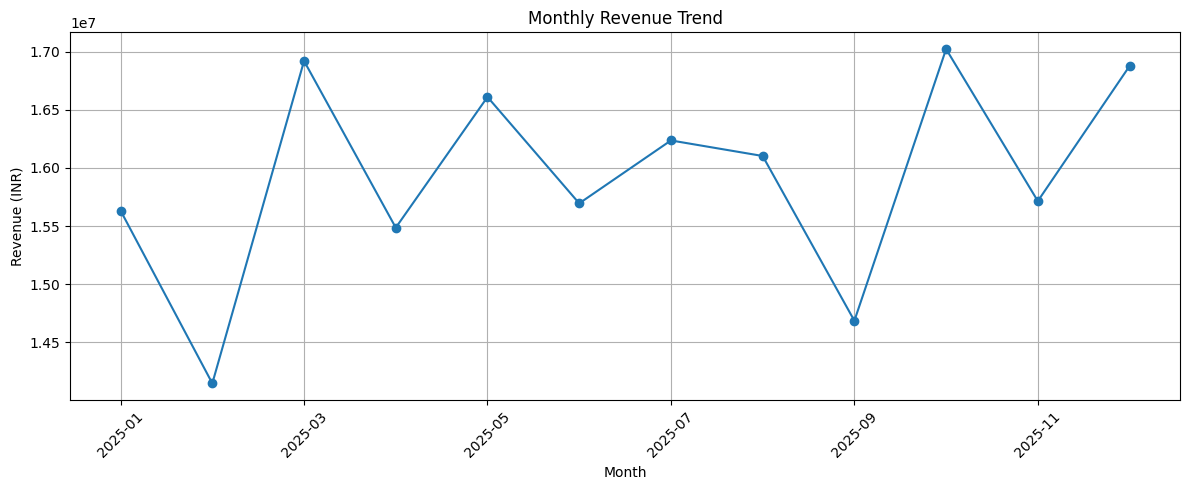

In [5]:
import matplotlib.pyplot as plt

monthly_revenue_float = monthly_revenue.copy()
monthly_revenue_float.index = monthly_revenue_float.index.astype(str)

monthly_revenue_float.plot(kind="line", marker="o", figsize=(12, 5))

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (INR)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()